In [3]:
# Action: import libraries
import pandas as pd # loading, cleaning and analysing the data
import numpy as np # numerical operations, if required
import requests # communicate with websites and web APIs using HTTP requests
import re # regular expressions for searching, matching and modifying text patterns
import time # functions for working with time, delays and timestamps

from bs4 import BeautifulSoup # parse and extract information from HTML or XML pages
from collections import Counter # counts how often items appear in an iterable

import matplotlib.pyplot as plt # creates graphs
import seaborn as sns # creates graphs

# visual configuration settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

print("Libraries successfully imported")

Libraries successfully imported


In [15]:
# Loading the dataset and inspecting
survey_df = pd.read_csv("data/employee_benefits_analysis_clean.csv")
print("Dataset dimensions", survey_df.shape)

print("\nColumns:")
print(survey_df.columns.tolist())

print("\nData types:")
survey_df.info()

print("\nMissing values:")
display(survey_df.isna().sum().sort_values(ascending=False))

Dataset dimensions (899, 7)

Columns:
['tech_company', 'benefits', 'workplace_resources', 'mh_employer_discussion', 'mh_coworker_discussion', 'medical_coverage', 'mental_health']

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 899 entries, 0 to 898
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   tech_company            899 non-null    str  
 1   benefits                899 non-null    str  
 2   workplace_resources     899 non-null    str  
 3   mh_employer_discussion  899 non-null    str  
 4   mh_coworker_discussion  899 non-null    str  
 5   medical_coverage        899 non-null    str  
 6   mental_health           899 non-null    str  
dtypes: str(7)
memory usage: 71.5 KB

Missing values:


tech_company              0
benefits                  0
workplace_resources       0
mh_employer_discussion    0
mh_coworker_discussion    0
medical_coverage          0
mental_health             0
dtype: int64

In [5]:
# Inspecting response distributions
survey_df.columns.tolist()

['tech_company',
 'benefits',
 'workplace_resources',
 'mh_employer_discussion',
 'mh_coworker_discussion',
 'medical_coverage',
 'mental_health']

In [6]:
for column in survey_df.columns:
    print(f"\n{column}")
    print(survey_df[column].value_counts(dropna=False))


tech_company
tech_company
Yes    899
Name: count, dtype: int64

benefits
benefits
Yes             561
I don't know    229
No              109
Name: count, dtype: int64

workplace_resources
workplace_resources
No              356
Yes             288
I don't know    255
Name: count, dtype: int64

mh_employer_discussion
mh_employer_discussion
No     574
Yes    325
Name: count, dtype: int64

mh_coworker_discussion
mh_coworker_discussion
No     466
Yes    433
Name: count, dtype: int64

medical_coverage
medical_coverage
Yes    823
No      76
Name: count, dtype: int64

mental_health
mental_health
Yes           392
No            259
Possibly      182
Don't Know     66
Name: count, dtype: int64


In [7]:
# Calculating the percentages
for column in survey_df.columns:
    percentages = survey_df[column].value_counts(normalize=True) * 100
    print(f"\n{column}")
    print(percentages.round(2))


tech_company
tech_company
Yes    100.0
Name: proportion, dtype: float64

benefits
benefits
Yes             62.40
I don't know    25.47
No              12.12
Name: proportion, dtype: float64

workplace_resources
workplace_resources
No              39.60
Yes             32.04
I don't know    28.36
Name: proportion, dtype: float64

mh_employer_discussion
mh_employer_discussion
No     63.85
Yes    36.15
Name: proportion, dtype: float64

mh_coworker_discussion
mh_coworker_discussion
No     51.84
Yes    48.16
Name: proportion, dtype: float64

medical_coverage
medical_coverage
Yes    91.55
No      8.45
Name: proportion, dtype: float64

mental_health
mental_health
Yes           43.60
No            28.81
Possibly      20.24
Don't Know     7.34
Name: proportion, dtype: float64


In [9]:
# Analysing the different benefits related columns
survey_df[
    [
        "benefits",
        "workplace_resources",
        "medical_coverage",
        "mental_health"
    ]
].apply(lambda column: column.value_counts(normalize=True) * 100)

,benefits,workplace_resources,medical_coverage,mental_health
Don't Know,NaN,NaN,NaN,7.341491
I don't know,25.472747,28.364850,NaN,NaN
No,12.124583,39.599555,8.453838,28.809789
Possibly,NaN,NaN,NaN,20.244716
Yes,62.402670,32.035595,91.546162,43.604004


In [11]:
# Comparing respondents that state having benefits with the other groups
benefits_wr_table = pd.crosstab(
    survey_df["benefits"],
    survey_df["workplace_resources"],
    normalize="index"
).mul(100).round(2)
benefits_wr_table

workplace_resources,I don't know,No,Yes
benefits,,,
I don't know,43.23,47.16,9.61
No,15.60,77.06,7.34
Yes,24.78,29.23,45.99


Among respondents who report having benefits versus respondents who report not having benefits, the percentage that report having access to workplace resources is 45.99

In [13]:
# Comparing respondents that state having benefits with the other groups
benefits_mh_table = pd.crosstab(
    survey_df["benefits"],
    survey_df["mental_health"],
    normalize="index"
).mul(100).round(2)
benefits_mh_table

mental_health,Don't Know,No,Possibly,Yes
benefits,,,,
I don't know,13.10,35.37,25.76,25.76
No,7.34,27.52,22.94,42.20
Yes,4.99,26.38,17.47,51.16


Among respondents who report having benefits versus respondents who report not having benefits, the percentage that report having a mental health condition is 51.16

In [14]:
# Comparing respondents that state having mental health discussions
discussion_mh_table = pd.crosstab(
    survey_df["mh_employer_discussion"],
    survey_df["mh_coworker_discussion"],
    normalize="index"
).mul(100).round(2)
discussion_mh_table

mh_coworker_discussion,No,Yes
mh_employer_discussion,,
No,68.82,31.18
Yes,21.85,78.15


Among respondents who report having mental health discussions with their employer, the percentage of respondents that also discuss mental health with their coworker is higher, 78.15% versus respondents who don't have mental health discussions either with the employer or with the coworkers , 68.82%.

In [15]:
analysis_columns = [
    "benefits",
    "workplace_resources",
    "mh_employer_discussion",
    "mh_coworker_discussion",
    "medical_coverage",
    "mental_health"
]

yes_no_df = survey_df[analysis_columns].apply(
    lambda column: column.eq("Yes").astype(int)
)

yes_percentages = yes_no_df.mean().mul(100).sort_values(ascending=False)

print(yes_percentages.round(2))

medical_coverage          91.55
benefits                  62.40
mh_coworker_discussion    48.16
mental_health             43.60
mh_employer_discussion    36.15
workplace_resources       32.04
dtype: float64


In [16]:
dont_know_percentages = (
    survey_df[analysis_columns]
    .apply(lambda column: column.eq("I don't know").mean() * 100)
    .sort_values(ascending=False)
)

print(dont_know_percentages.round(2))

workplace_resources       28.36
benefits                  25.47
mh_employer_discussion     0.00
mh_coworker_discussion     0.00
medical_coverage           0.00
mental_health              0.00
dtype: float64


The percentage of employees who are not aware of available benefits or how to access the resources is around a quarter of the respondents.

In [20]:
#Preparing the employee survey data for comparision with the survey dataset
survey_df["benefits_numeric"] = (
    survey_df["benefits"]
    .map({"Yes": 1, "No": 0, "I don't know": 0})
)

support_rates = survey_df.groupby("workplace_resources").agg(
    support_rate=("benefits_numeric", "mean")
).reset_index()

support_rates

,workplace_resources,support_rate
0,I don't know,0.545098
1,No,0.460674
2,Yes,0.895833


In [63]:
# Keyword analysis on each selected tech company website
websites = {
    "GitLab": "https://handbook.gitlab.com/handbook/total-rewards/benefits/",
    "Apple": "https://www.apple.com/careers/uk/life-at-apple/benefits.html",
    "Salesforce": "https://www.salesforce.com/blog/complete-guide-salesforce-benefits/"
}

keywords = {
    "Mental health": [
        "mental health",
        "mental healthcare",
        "mental wellbeing",
        "mental wellness"
    ],

    "Professional support": [
        "counselling",
        "counseling",
        "therapy",
        "therapist",
        "psychologist",
        "psychiatrist"
    ],

    "Wellbeing resources": [
        "wellbeing",
        "wellness",
        "employee assistance",
        "wellbeing coaching"
    ],

    "Workplace well-being": [
        "stress management",
        "burnout",
        "work-life balance",
        "emotional wellbeing",
        "resilience"
    ]
}

def extract_page_text(url):

    response = requests.get(
        url,
        headers={"User-Agent": "Mozilla/5.0"},
        timeout=30
    )

    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    # Remove irrelevant page elements
    for element in soup.select(
        "nav, footer, header, script, style, noscript"
    ):
        element.decompose()

    # Extract main content
    content = (
        soup.find("main")
        or soup.find("article")
        or soup.find("body")
    )

    return content.get_text(" ", strip=True).lower()


results = []
diagnostics = []

for company, url in websites.items():

    try:
        page_text = extract_page_text(url)

        total_words = len(page_text.split())

        diagnostics.append({
            "Company": company,
            "Extracted characters": len(page_text),
            "Total words": total_words
        })

        for category, terms in keywords.items():

            category_count = 0

            for term in terms:

                pattern = r"\b" + re.escape(term.lower()) + r"\b"

                category_count += len(
                    re.findall(pattern, page_text)
                )

            results.append({
                "Company": company,
                "Category": category,
                "Keyword Count": category_count,
                "Total Words": total_words,
                "Mentions per 1000 Words": round(
                    category_count / total_words * 1000, 2
                ) if total_words else 0
            })

    except requests.RequestException as error:
        print(f"Error scraping {company}: {error}")


website_analysis = pd.DataFrame(results)

diagnostic_table = pd.DataFrame(diagnostics)

print("EXTRACTION CHECK")
print(diagnostic_table)

print("\nKEYWORD ANALYSIS")
print(website_analysis)

EXTRACTION CHECK
      Company  Extracted characters  Total words
0      GitLab                  6016          884
1       Apple                  4580          747
2  Salesforce                 10195         1588

KEYWORD ANALYSIS
       Company              Category  Keyword Count  Total Words  \
0       GitLab         Mental health              0          884   
1       GitLab  Professional support              0          884   
2       GitLab   Wellbeing resources              1          884   
3       GitLab  Workplace well-being              0          884   
4        Apple         Mental health              1          747   
5        Apple  Professional support              1          747   
6        Apple   Wellbeing resources              0          747   
7        Apple  Workplace well-being              0          747   
8   Salesforce         Mental health              7         1588   
9   Salesforce  Professional support              7         1588   
10  Salesforce   Well

In [62]:
# Checking how the scraping is working
for company, url in websites.items():

    response = requests.get(
        url,
        headers={"User-Agent": "Mozilla/5.0"},
        timeout=20
    )

    soup = BeautifulSoup(response.text, "html.parser")
    page_text = soup.get_text(" ", strip=True)

    print(f"\n--- {company} ---")
    print("Status:", response.status_code)
    print("URL:", response.url)
    print("HTML characters:", len(response.text))
    print("Extracted text characters:", len(page_text))
    print("\nText preview:")
    print(page_text[:1000])


--- GitLab ---
Status: 200
URL: https://handbook.gitlab.com/handbook/total-rewards/benefits/
HTML characters: 2326588
Extracted text characters: 112839

Text preview:
Benefits | The GitLab Handbook The GitLab Handbook GitLab Handbook Toggle theme Light Dark Auto The Handbook About GitLab AMAs Being a public company Cadence E-Group offsite Be clear about sticky bears E-Group Weekly Family and Friends Day GitLab All-Company Meetings GitLab Culture Executive Connect events All Remote A complete guide to the benefits of an all-remote company All-Remote Meetings Building and reinforcing a sustainable remote work culture Combating burnout, isolation, and anxiety in the remote workplace Considerations for working while traveling GitLab for Remote Teams GitLab Meeting Best Practices: Live Doc Meetings GitLab's Guide to All-Remote Remote Guide for Design Teams Remote Guide for Finance Teams Remote Guide for Legal Teams Remote Guide for People Operations How do you collaborate and whiteboard re

In [64]:
# Checking what was extracted
for company, url in websites.items():

    text = extract_page_text(url)

    print(f"\n--- {company} ---")
    print(text[:2000])


--- GitLab ---
benefits overview of gitlab’s benefit philosophy and get support with questions related benefits pages general & entity specific benefits modern health parental leave and return tool kit for gitlab managers and team members we’ve got you covered: our benefits philosophy clear benefits, real support at gitlab, we believe team member benefits should be simple to understand and there when you need them. from life’s big moments to everyday questions, our comprehensive coverage gives you clarity and confidence so you can focus on your work and life. whether you’re planning for the future, starting a family, caring for aging parents, or dealing with unexpected challenges, gitlab’s benefits are designed to support you at every stage of life—with comprehensive coverage and transparent information when you need it most. your support team and resources need help with your benefits? rest easy knowing you have multiple resources at your fingertips: start here: this handbook is your

In [16]:
# Inspecting the context of each keyword
def find_keyword_context(text, terms):

    for term in terms:

        pattern = r"\b" + re.escape(term) + r"\b"

        for match in re.finditer(pattern, text, re.IGNORECASE):

            start = max(0, match.start() - 100)
            end = min(len(text), match.end() + 100)

            print(f"\nKeyword: {term}")
            print(text[start:end])

In [58]:
# Creating a summary dataframe
summary = (
    website_analysis
    .groupby(["Company", "Category"])["Count"]
    .sum()
    .reset_index()
)

print(summary)

       Company              Category  Count
0        Apple     Emotional support      0
1        Apple       Medical support      5
2        Apple         Mental health      1
3        Apple  Professional support      4
4        Apple     Work-life balance      0
5       GitLab     Emotional support      0
6       GitLab       Medical support      4
7       GitLab         Mental health      0
8       GitLab  Professional support     12
9       GitLab     Work-life balance      2
10  Salesforce     Emotional support      6
11  Salesforce       Medical support      6
12  Salesforce         Mental health     10
13  Salesforce  Professional support     18
14  Salesforce     Work-life balance      2


In [71]:
# Dataframe with one row per company
pivot_df = summary.pivot(
    index="Company",
    columns="Category",
    values="Count"
).fillna(0)

print(pivot_df)

Category    Emotional support  Medical support  Mental health  \
Company                                                         
Apple                       0                5              1   
GitLab                      0                4              0   
Salesforce                  6                6             10   

Category    Professional support  Work-life balance  
Company                                              
Apple                          4                  0  
GitLab                        12                  2  
Salesforce                    18                  2  


In [86]:
# Creatimng the folder to save the dataframe in 
from pathlib import Path

# Definingthe project folder
project_folder = Path("/Users/sandragoncalves/Desktop/git-projects/beyond_benefits")
data_folder = project_folder / "data"

data_folder.mkdir(parents=True, exist_ok=True)

file_path = data_folder / "pivot_df.csv"
pivot_df.to_csv(file_path, index=True)

print(file_path)
print(file_path.exists())

/Users/sandragoncalves/Desktop/git-projects/beyond_benefits/data/pivot_df.csv
True


In [88]:
import os

os.chdir("/Users/sandragoncalves/Desktop/git-projects/beyond_benefits")

print(os.getcwd())

file_path = Path("data") / "pivot_df.csv"

pivot_df = pd.read_csv(file_path, index_col=0)

/Users/sandragoncalves/Desktop/git-projects/beyond_benefits


In [89]:
pivot_df = pd.read_csv("data/pivot_df.csv", index_col=0)

pivot_df

,Emotional support,Medical support,Mental health,Professional support,Work-life balance,Total mentions
Company,,,,,,
Apple,0,5,1,4,0,10
GitLab,0,4,0,12,2,18
Salesforce,6,6,10,18,2,42


In [72]:
# Comparing total keyword mentions
pivot_df["Total mentions"] = pivot_df.sum(axis=1)

print(pivot_df["Total mentions"].sort_values(ascending=False))

Company
Salesforce    42
GitLab        18
Apple         10
Name: Total mentions, dtype: int64


Results:
Salesforce has the most total keyword mentions.
GitLab has many professional-support mentions.
Apple has fewer mentions overall.
Salesforce has the highest number of mental-health keyword matches.
However, this does not measure the quality or availability of actual benefits.

In [74]:
# Comparing topic proportions
category_columns = summary["Category"].unique()

pivot_df["Total mentions"] = pivot_df[category_columns].sum(axis=1)

percentage_df = pivot_df[category_columns].div(
    pivot_df["Total mentions"],
    axis=0
).mul(100).round(2)

print(percentage_df)

Category    Emotional support  Medical support  Mental health  \
Company                                                         
Apple                    0.00            50.00          10.00   
GitLab                   0.00            22.22           0.00   
Salesforce              14.29            14.29          23.81   

Category    Professional support  Work-life balance  
Company                                              
Apple                      40.00               0.00  
GitLab                     66.67              11.11  
Salesforce                 42.86               4.76  


Salesforce has the highest number of keyword mentions to directly related with mental health: Emotional support (14.29%), Mental health (23.81 and Work-life balance (4.76%). But this does not mean that this company offers more mental health benefits.

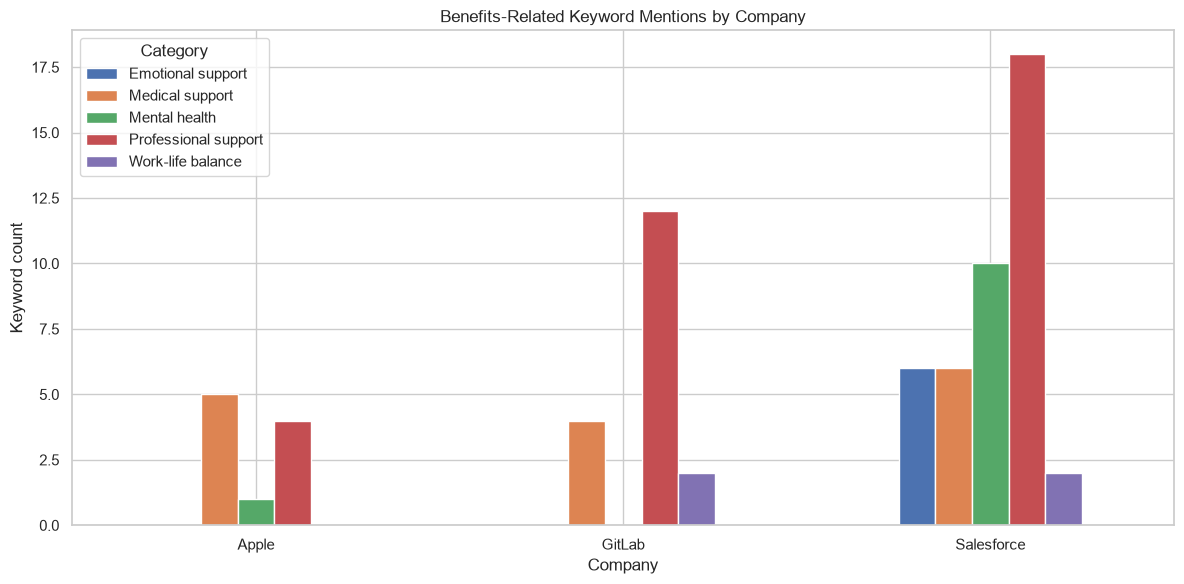

In [75]:
# Visualizing the topic distribution
pivot_df[category_columns].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Benefits-Related Keyword Mentions by Company")
plt.xlabel("Company")
plt.ylabel("Keyword count")
plt.xticks(rotation=0)
plt.legend(title="Category")
plt.tight_layout()
plt.show()

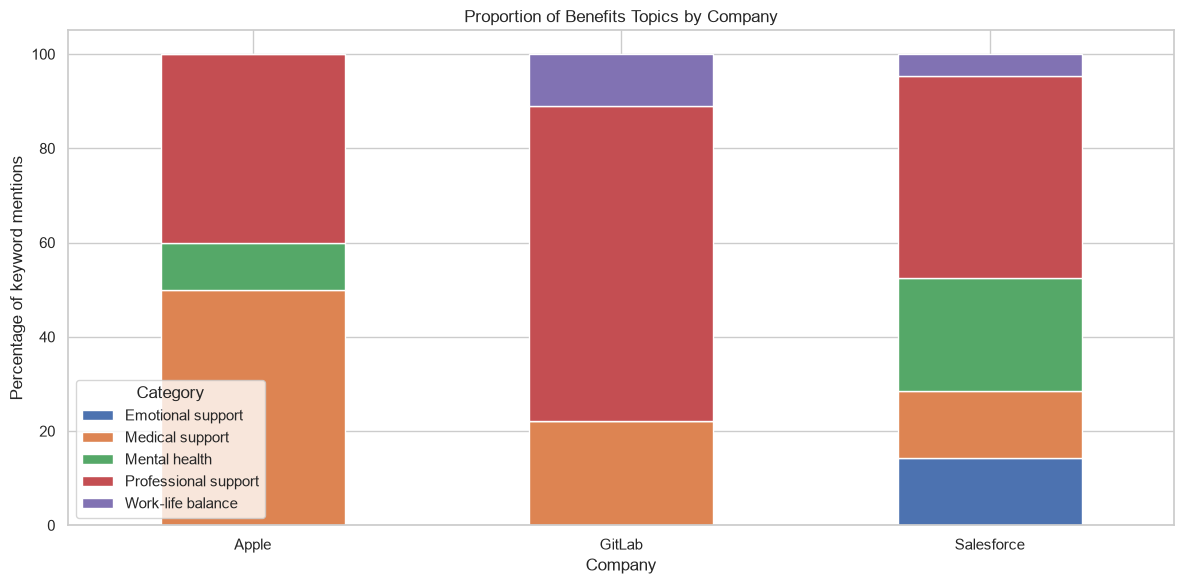

In [76]:
# Visualizing proportions
percentage_df.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Proportion of Benefits Topics by Company")
plt.xlabel("Company")
plt.ylabel("Percentage of keyword mentions")
plt.xticks(rotation=0)
plt.legend(title="Category")
plt.tight_layout()
plt.show()

We have descriptive findings but the hypothesis 4 is still to be tested. The analysed categories do not specifically represent access instructions. 